In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import sys
sys.path.append("../src")

In [4]:
DATA_PATH = "../data/simulation/bdt_ctmc_window/0/T_extant.json"

In [5]:
from simulator import load_tree

T, root = load_tree(DATA_PATH)
T

In [6]:
T.nodes(data=True)

NodeDataView({0: {'time': 0.0, 'event': 'root', 'state': 'A'}, 1: {'time': 0.11053812613376528, 'event': 'birth', 'state': 'A'}, 2: {'time': 0.3664782618191315, 'event': 'birth', 'state': 'A'}, 3: {'time': 0.17465084459238117, 'event': 'birth', 'state': 'A'}, 4: {'time': 0.20016234880976538, 'event': 'birth', 'state': 'A'}, 5: {'time': 0.31222654828239355, 'event': 'birth', 'state': 'A'}, 7: {'time': 0.22014565433645428, 'event': 'birth', 'state': 'A'}, 8: {'time': 0.49832865875713434, 'event': 'birth', 'state': 'A'}, 9: {'time': 0.3485435885594576, 'event': 'birth', 'state': 'A'}, 11: {'time': 0.5358617982310684, 'event': 'birth', 'state': 'A'}, 12: {'time': 0.5063315406371854, 'event': 'birth', 'state': 'A'}, 13: {'time': 0.3651990021852279, 'event': 'birth', 'state': 'A'}, 16: {'time': 0.3667934714901844, 'event': 'birth', 'state': 'A'}, 17: {'time': 0.5457774126302132, 'event': 'birth', 'state': 'A'}, 18: {'time': 0.38770714137720125, 'event': 'birth', 'state': 'A'}, 19: {'time': 0

In [7]:
T.edges(data=True)

OutEdgeDataView([(0, 1, {'start_time': 0.0, 'end_time': 0.11053812613376528, 'length': 0.11053812613376528}), (1, 2, {'start_time': 0.11053812613376528, 'end_time': 0.3664782618191315, 'length': 0.2559401356853662}), (1, 3, {'start_time': 0.11053812613376528, 'end_time': 0.17465084459238117, 'length': 0.0641127184586159}), (2, 16, {'start_time': 0.3664782618191315, 'end_time': 0.3667934714901844, 'length': 0.0003152096710528629}), (2, 17, {'start_time': 0.3664782618191315, 'end_time': 0.5457774126302132, 'length': 0.17929915081108166}), (3, 4, {'start_time': 0.17465084459238117, 'end_time': 0.20016234880976538, 'length': 0.025511504217384212}), (3, 5, {'start_time': 0.17465084459238117, 'end_time': 0.31222654828239355, 'length': 0.13757570369001237}), (4, 7, {'start_time': 0.20016234880976538, 'end_time': 0.22014565433645428, 'length': 0.019983305526688894}), (4, 107, {'start_time': 0.20016234880976538, 'end_time': 0.8604646489527551, 'length': 0.6603023001429897}), (5, 11, {'start_tim

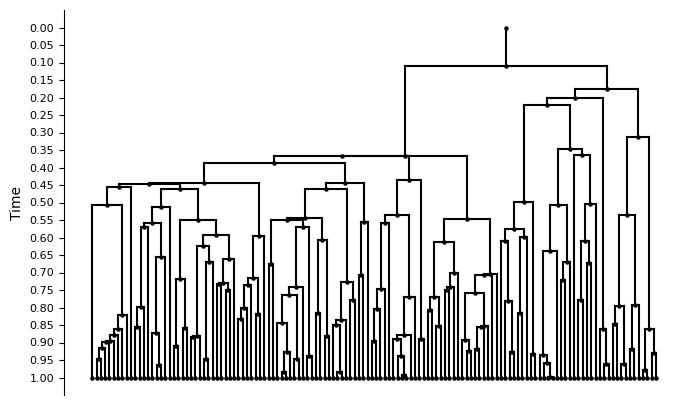

In [8]:
from plotters import draw_ultrametric_tree

draw_ultrametric_tree(T, root=root, add_labels=False)

In [9]:
from collections import defaultdict

cell_state_counts = defaultdict(int)

for node, d in T.nodes(data=True):
    if 'state' in d:
        cell_state_counts[d.get('state')] += 1

cell_state_counts

defaultdict(int, {'A': 76, 'B': 94, 'C': 94})

In [10]:
from likelihood import add_node_times

T = add_node_times(T, root=root)

In [11]:
T.nodes(data=True)

NodeDataView({0: {'time': 0.0, 'event': 'root', 'state': 'A', 'T': 1}, 1: {'time': 0.11053812613376528, 'event': 'birth', 'state': 'A', 'T': 0.8894618738662348}, 2: {'time': 0.3664782618191315, 'event': 'birth', 'state': 'A', 'T': 0.6335217381808684}, 3: {'time': 0.17465084459238117, 'event': 'birth', 'state': 'A', 'T': 0.8253491554076189}, 4: {'time': 0.20016234880976538, 'event': 'birth', 'state': 'A', 'T': 0.7998376511902346}, 5: {'time': 0.31222654828239355, 'event': 'birth', 'state': 'A', 'T': 0.6877734517176064}, 7: {'time': 0.22014565433645428, 'event': 'birth', 'state': 'A', 'T': 0.7798543456635457}, 8: {'time': 0.49832865875713434, 'event': 'birth', 'state': 'A', 'T': 0.5016713412428657}, 9: {'time': 0.3485435885594576, 'event': 'birth', 'state': 'A', 'T': 0.6514564114405423}, 11: {'time': 0.5358617982310684, 'event': 'birth', 'state': 'A', 'T': 0.4641382017689316}, 12: {'time': 0.5063315406371854, 'event': 'birth', 'state': 'A', 'T': 0.49366845936281456}, 13: {'time': 0.36519

In [18]:
from scipy.special import logsumexp
import networkx as nx
import numpy as np
from math import log, ceil, floor


def calculate_log_likelihood_ctmc(
    T: nx.DiGraph,
    birth_rates: np.ndarray,
    death_rates: np.ndarray,
    sampling_rate: float,
    transition_probabilities: np.ndarray,
    one_by_delta_t: int = 1000,
    transition_filter: np.ndarray = None,
):

    num_states = len(birth_rates)
    delta_t = 1.0 / one_by_delta_t

    ####################################################################
    # Extinction probabilities U
    ####################################################################

    U = np.zeros((one_by_delta_t + 1, num_states))
    U[0, :] = 1.0 - sampling_rate

    for t in range(1, one_by_delta_t + 1):

        for s in range(num_states):

            next_transition_sum = sum(
                    transition_probabilities[s, d]
                    * delta_t
                    * U[t - 1, d]
                    for d in range(num_states)
                    if d != s
                    and (transition_filter is None or transition_filter[t, s, d])
            )

            U[t, s] = (
                (1.0
                 - (birth_rates[s]
                    + death_rates[s]
                    + transition_probabilities[s, :].sum())
                 * delta_t)
                * U[t - 1, s]
                + birth_rates[s]
                * delta_t
                * U[t - 1, s] ** 2
                + death_rates[s] * delta_t
                + next_transition_sum
            )

    ####################################################################
    # Postorder edge list
    ####################################################################

    postorder_edges = []

    for parent in nx.dfs_postorder_nodes(T):
        for child in T.successors(parent):
            postorder_edges.append((parent, child))

    edge_to_idx = {
        edge: idx
        for idx, edge in enumerate(postorder_edges)
    }
    num_edges = len(postorder_edges)

    ####################################################################
    # LL[e,s]
    # likelihood at parent end of edge
    ####################################################################

    LL = np.full((num_edges, num_states), -np.inf)

    ####################################################################
    # Process edges bottom-up
    ####################################################################

    for edge_idx, (u, v) in enumerate(postorder_edges):

        parent_time = T.nodes[u]["T"]
        child_time = T.nodes[v]["T"]

        children = list(T.successors(v))

        ###############################################################
        # likelihood at child event
        ###############################################################

        if len(children) == 0:

            child_state = ord(T.nodes[v]["state"]) - ord('A')

            initial = np.full(num_states, -np.inf)
            initial[child_state] = log(sampling_rate)

        elif len(children) == 2:

            c1, c2 = children

            LL1 = LL[edge_to_idx[(v,c1)]]
            LL2 = LL[edge_to_idx[(v,c2)]]

            if np.all(np.isneginf(LL1)):
                print("child edge not computed", (v,c1))

            if np.all(np.isneginf(LL2)):
                print("child edge not computed", (v,c2))

            initial = (
                np.log(birth_rates)
                + np.log(delta_t)
                + LL1
                + LL2
            )

        else:
            raise ValueError(
                f"Node {v} has {len(children)} children. "
                "Tree must be binary."
            )

        ###############################################################
        # discretized branch
        ###############################################################

        e_t = int(round(child_time * one_by_delta_t))
        s_t = int(round(parent_time * one_by_delta_t))

        e_t = min(max(e_t, 0), one_by_delta_t)
        s_t = min(max(s_t, 0), one_by_delta_t)

        # print(f"Processing edge {(u,v)}: child_time={child_time}, parent_time={parent_time}, e_t={e_t}, s_t={s_t}")

        previous = initial.copy()

        ###############################################################
        # propagate from child -> parent
        ###############################################################

        for t in range(e_t, s_t):

            current = np.full(num_states, -np.inf)

            total_rate = (
                birth_rates
                + death_rates
                + transition_probabilities.sum(axis=1)
            )

            A = (
                1.0
                - total_rate * delta_t
                + 2.0
                * birth_rates
                * U[t - 1, :]
                * delta_t
            )

            for s in range(num_states):

                terms = []

                if A[s] > 0:
                    terms.append(
                        np.log(A[s]) + previous[s]
                    )

                for d in range(num_states):

                    if d == s:
                        continue

                    if transition_filter is not None and not transition_filter[t, s, d]:
                        continue

                    q = transition_probabilities[s, d]

                    if q > 0:
                        terms.append(
                            np.log(q * delta_t)
                            + previous[d]
                        )

                current[s] = logsumexp(terms)

            previous = current

        LL[edge_idx] = previous

    ####################################################################
    # Root likelihood
    ####################################################################

    root = next(
        n for n in T.nodes
        if T.in_degree(n) == 0
    )

    root_children = list(T.successors(root))

    if len(root_children) != 1:
        raise ValueError(
            "Expected a dummy root with one child."
        )

    root_edge = edge_to_idx[(root, root_children[0])]

    print("LL at root edge:", root_edge, LL[root_edge])

    root_loglikelihood = LL[root_edge, 0]

    return root_loglikelihood, LL, U



transition_filter = np.zeros(
    (1001, 3, 3),
    dtype=bool
)

# 0 <= t <= 50
transition_filter[:51] = np.array([
    [False, False,  False],
    [False, False, False],
    [False, False, False],
])

# 51 <= t <= 600
transition_filter[51:601] = np.array([
    [False, True,  True],
    [False, False, True],
    [False, False, False],
])

# 601 <= t <= 1000
transition_filter[601:] = np.array([
    [False, False, False],
    [False, False, False],
    [False, False, False],
])


calculate_log_likelihood_ctmc(
    T,
    birth_rates=np.array([7.0, 5.5, 3.5]),
    death_rates=np.array([0.1, 0.1, 0.1]),
    sampling_rate=0.5,
    transition_probabilities=np.array([
                [0.0, 1.0, 1.5],
                [0.0, 0.0, 0.8],
                [0.0, 0.0, 0.0],
    ]),
    one_by_delta_t=1000,
    transition_filter=transition_filter
)

LL at root edge: 262 [-950.67071007          -inf          -inf]


(np.float64(-950.6707100742628),
 array([[-6.98501139e+00, -7.70883142e-01,            -inf],
        [-6.98501139e+00, -7.70883142e-01,            -inf],
        [-1.03508877e+01, -6.80615205e+00,            -inf],
        [-4.31535035e+00, -8.32261721e-01,            -inf],
        [-1.69142020e+01, -1.28814671e+01,            -inf],
        [-3.95375758e+00, -8.72307848e-01,            -inf],
        [-2.40846776e+01, -1.89692640e+01,            -inf],
        [-3.87636359e+00, -8.84789713e-01,            -inf],
        [-2.92896055e+01, -2.50963805e+01,            -inf],
        [-3.69264405e+00, -9.24109378e-01,            -inf],
        [-3.52052672e+01, -3.12772301e+01,            -inf],
        [-3.53148951e+00, -9.77842374e-01,            -inf],
        [-4.08351210e+01, -3.75813838e+01,            -inf],
        [-3.34681533e+00, -1.10114655e+00,            -inf],
        [-2.72815792e+00, -2.96375456e+00, -1.36403233e+00],
        [-4.69306261e+01, -4.53263119e+01,          

In [19]:
types = ["A", "B", "C"]

transition_maps = [
    ("A", ["B", "C"]),
    ("B", ["C"]),
]

In [27]:
transition_filter = np.zeros(
    (101, 3, 3),
    dtype=bool
)

# 0 <= t <= 9
transition_filter[:9] = np.array([
    [False, False,  False],
    [False, False, False],
    [False, False, False],
])

# 9 <= t <= 60
transition_filter[9:51] = np.array([
    [False, True,  True],
    [False, False, True],
    [False, False, False],
])

# 51 <= t <= 100
transition_filter[51:101] = np.array([
    [False, False, False],
    [False, False, False],
    [False, False, False],
])

In [28]:
import numpy as np
from scipy.optimize import minimize
from scipy.special import expit as sigmoid

MAX_DEATH = 1.0
MAX_BIRTH = 10.0
MAX_TRANSITION = 5.0


def unpack_params(theta):

    k = 0

    ####################################################
    # death rates
    ####################################################

    death = np.zeros(len(types))

    for i in range(len(types)):
        death[i] = MAX_DEATH * sigmoid(theta[k])
        k += 1

    ####################################################
    # birth rates
    ####################################################

    birth = np.zeros(len(types))

    for i in range(len(types)):
        birth[i] = (
            death[i]
            + (MAX_BIRTH - death[i]) * sigmoid(theta[k])
        )
        k += 1

    ####################################################
    # transition rates
    ####################################################

    Q = np.zeros((len(types), len(types)))

    type_to_idx = {
        t: i
        for i, t in enumerate(types)
    }

    for src, transition_to in transition_maps:

        i = type_to_idx[src]

        for dst in transition_to:

            j = type_to_idx[dst]

            Q[i, j] = (
                MAX_TRANSITION
                * sigmoid(theta[k])
            )

            k += 1

    return birth, death, Q


def pack_initial():

    params = []

    # death parameters
    params.extend([0.0] * len(types))

    # birth parameters
    params.extend([0.0] * len(types))

    # transition parameters
    for _, transition_to in transition_maps:
        params.extend([0.0] * len(transition_to))

    return np.array(params)


def neg_log_likelihood(theta, trees, sampling_rate=0.5):

    birth, death, Q = unpack_params(theta)

    total_nll = 0.0

    for tree in trees:

        ll, _, _ = calculate_log_likelihood_ctmc(
            T=tree,
            birth_rates=birth,
            death_rates=death,
            sampling_rate=sampling_rate,
            transition_probabilities=Q,
            one_by_delta_t=100,
            transition_filter=transition_filter,
        )

        total_nll -= ll

    print(
        f"NLL={total_nll:.6f}",
        f"birth={birth}",
        f"death={death}",
    )

    return total_nll


def find_params(trees, sampling_rate=0.5):

    theta0 = pack_initial()

    result = minimize(
        neg_log_likelihood,
        theta0,
        args=(trees, sampling_rate),
        method="L-BFGS-B",
        options={
            "disp": True,
            "maxiter": 500,
        },
    )

    birth, death, Q = unpack_params(result.x)

    print("\nOptimization finished")
    print("Success:", result.success)
    print("Message:", result.message)
    print("Log-likelihood:", -result.fun)
    print("Birth rates:", birth)
    print("Death rates:", death)
    print("Transition rates:")
    print(Q)

    return birth, death, Q, result

In [29]:
find_params([T])

/var/folders/nz/jn74t1g51q10qyclfkkr8cgm0000gq/T/ipykernel_42634/419358822.py:116: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  result = minimize(


LL at root edge: 262 [-680.95911101          -inf          -inf]
NLL=680.959111 birth=[5.25 5.25 5.25] death=[0.5 0.5 0.5]
LL at root edge: 262 [-680.95911101          -inf          -inf]
NLL=680.959111 birth=[5.25 5.25 5.25] death=[0.5 0.5 0.5]
LL at root edge: 262 [-680.95911101          -inf          -inf]
NLL=680.959111 birth=[5.25 5.25 5.25] death=[0.5 0.5 0.5]
LL at root edge: 262 [-680.95911101          -inf          -inf]
NLL=680.959111 birth=[5.25 5.25 5.25] death=[0.5 0.5 0.5]
LL at root edge: 262 [-680.95911098          -inf          -inf]
NLL=680.959111 birth=[5.25000002 5.25       5.25      ] death=[0.5 0.5 0.5]
LL at root edge: 262 [-680.95911098          -inf          -inf]
NLL=680.959111 birth=[5.25       5.25000002 5.25      ] death=[0.5 0.5 0.5]
LL at root edge: 262 [-680.95911111          -inf          -inf]
NLL=680.959111 birth=[5.25       5.25       5.25000002] death=[0.5 0.5 0.5]
LL at root edge: 262 [-680.95911108          -inf          -inf]
NLL=680.959111 birth

(array([5.84390813, 5.98767739, 3.60792211]),
 array([9.99974535e-01, 1.58593200e-09, 1.14055830e-32]),
 array([[0.        , 0.92430065, 1.58286097],
        [0.        , 0.        , 0.65066643],
        [0.        , 0.        , 0.        ]]),
   message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
   success: True
    status: 0
       fun: 658.4412898051816
         x: [ 1.058e+01 -2.026e+01 -7.355e+01  1.532e-01  4.003e-01
             -5.719e-01 -1.484e+00 -7.696e-01 -1.900e+00]
       nit: 33
       jac: [ 0.000e+00  0.000e+00  0.000e+00 -1.069e-03  2.444e-03
             -5.241e-03  5.571e-04  7.276e-04 -3.752e-04]
      nfev: 390
      njev: 39
  hess_inv: <9x9 LbfgsInvHessProduct with dtype=float64>)